In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
file_path = r"C:\Users\SHIVANI SAPKAL\Desktop\Data Science mini\Customer Churn Analysis and Prediction\data\raw\IBM Telco Customer Churn.csv"

df = pd.read_csv(file_path)

In [5]:
print("Dataset Shape:", df.shape)
print(df.head())
print(df.tail())

Dataset Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [6]:
print("COLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

COLUMN NAMES
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   On

In [9]:
df.isnull()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7039,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7040,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7041,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [12]:
print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nNumber of duplicate rows:", df.duplicated().sum())

if "customerID" in df.columns:
    print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Missing values in each column:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Number of duplicate rows: 0
Duplicate customer IDs: 0


In [13]:
print("Churn counts:")
display(df["Churn"].value_counts())

print("\nChurn percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

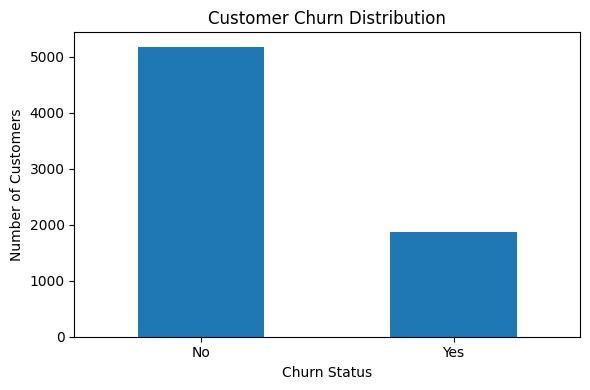

In [15]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(6, 4))
churn_counts.plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
print("TotalCharges data type:", df["TotalCharges"].dtype)

print("\nSample values:")
display(df["TotalCharges"].head(10))

print("\nValues that cannot be converted to numbers:")
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

invalid_values = df.loc[
    total_charges_numeric.isna(),
    ["customerID", "tenure", "TotalCharges", "Churn"]
]

print("Number of invalid values:", len(invalid_values))
display(invalid_values.head(10))

TotalCharges data type: object

Sample values:


0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object


Values that cannot be converted to numbers:
Number of invalid values: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


In [17]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

display(df[numeric_columns].describe())
#just understood total charges is sstored as text

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [18]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


customerID
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


In [19]:
# Keep the original data unchanged
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original dataset shape: (7043, 21)
Working copy shape: (7043, 21)


In [20]:
# Convert blank strings and whitespace-only values into missing values
df_clean["TotalCharges"] = df_clean["TotalCharges"].replace(
    r"^\s*$",
    pd.NA,
    regex=True
)

# Convert the column from text to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print("New data type:", df_clean["TotalCharges"].dtype)
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

display(
    df_clean.loc[
        df_clean["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

New data type: float64
Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [21]:
# Check whether all missing TotalCharges records have zero tenure
missing_total = df_clean["TotalCharges"].isna()

print(
    "Missing TotalCharges with zero tenure:",
    (df_clean.loc[missing_total, "tenure"] == 0).sum()
)

print(
    "Total missing TotalCharges:",
    missing_total.sum()
)

Missing TotalCharges with zero tenure: 11
Total missing TotalCharges: 11


In [22]:
# Documented treatment: zero tenure and no recorded total charges
df_clean.loc[missing_total, "TotalCharges"] = 0

print("Remaining missing TotalCharges:", df_clean["TotalCharges"].isna().sum())
print("Updated data type:", df_clean["TotalCharges"].dtype)

Remaining missing TotalCharges: 0
Updated data type: float64


In [23]:
print("Dataset shape after cleaning:", df_clean.shape)

print("\nMissing values:")
display(df_clean.isnull().sum().sort_values(ascending=False).head(10))

print("\nData types:")
display(df_clean.dtypes)

print("\nTotalCharges summary:")
display(df_clean["TotalCharges"].describe())

Dataset shape after cleaning: (7043, 21)

Missing values:


customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64


Data types:


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


TotalCharges summary:


count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

In [24]:
from pathlib import Path

PROJECT_ROOT = (
    Path.home()
    / "Desktop"
    / "Data Science mini"
    / "Customer Churn Analysis and Prediction"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = PROCESSED_DIR / "telco_churn_cleaned.csv"

df_clean.to_csv(OUTPUT_PATH, index=False)

print("Cleaned dataset saved to:")
print(OUTPUT_PATH)

Cleaned dataset saved to:
C:\Users\SHIVANI SAPKAL\Desktop\Data Science mini\Customer Churn Analysis and Prediction\data\processed\telco_churn_cleaned.csv


In [26]:
from pathlib import Path

# Load the saved cleaned dataset
PROJECT_ROOT = (
    Path.home()
    / "Desktop"
    / "Data Science mini"
    / "Customer Churn Analysis and Prediction"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "telco_churn_cleaned.csv"
)

df_clean = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_clean.shape)
print("Churn categories:", df_clean["Churn"].unique())

Dataset shape: (7043, 21)
Churn categories: ['No' 'Yes']


In [27]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

contract_churn = contract_churn.round(2)

print("Churn percentage within each contract type:")
display(contract_churn)

Churn percentage within each contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


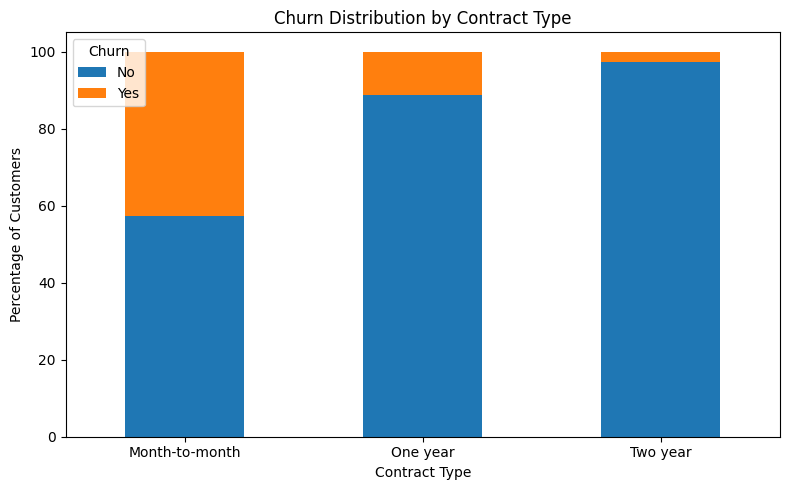

In [28]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [29]:
tenure_summary = (
    df_clean.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(tenure_summary)

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


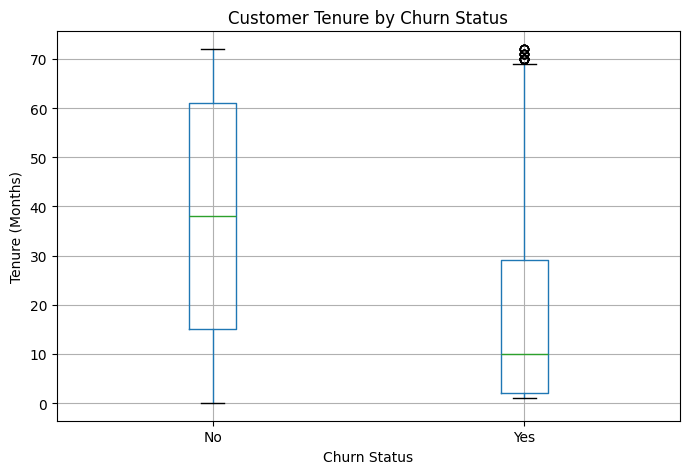

In [30]:
df_clean.boxplot(
    column="tenure",
    by="Churn",
    figsize=(7, 5)
)

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [31]:
charges_summary = (
    df_clean.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(charges_summary)

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


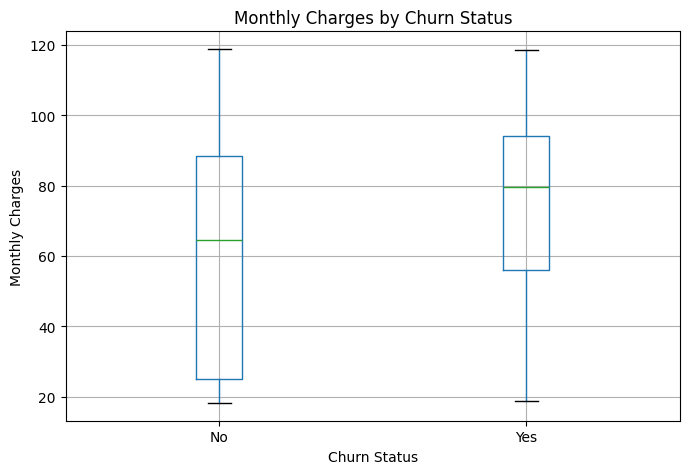

In [32]:
df_clean.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(7, 5)
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [33]:
def churn_rate_by_group(data, column):
    result = pd.crosstab(
        data[column],
        data["Churn"],
        normalize="index"
    ) * 100

    result = result.round(2)

    return result.sort_values("Yes", ascending=False)


print("Payment method:")
display(churn_rate_by_group(df_clean, "PaymentMethod"))

print("Internet service:")
display(churn_rate_by_group(df_clean, "InternetService"))

print("Online security:")
display(churn_rate_by_group(df_clean, "OnlineSecurity"))

print("Tech support:")
display(churn_rate_by_group(df_clean, "TechSupport"))

print("Senior citizen status:")
display(churn_rate_by_group(df_clean, "SeniorCitizen"))

Payment method:


Churn,No,Yes
PaymentMethod,,
Electronic check,54.71,45.29
Mailed check,80.89,19.11
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24


Internet service:


Churn,No,Yes
InternetService,,
Fiber optic,58.11,41.89
DSL,81.04,18.96
No,92.60,7.40


Online security:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
Yes,85.39,14.61
No internet service,92.60,7.40


Tech support:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
Yes,84.83,15.17
No internet service,92.60,7.40


Senior citizen status:


Churn,No,Yes
SeniorCitizen,,
1,58.32,41.68
0,76.39,23.61


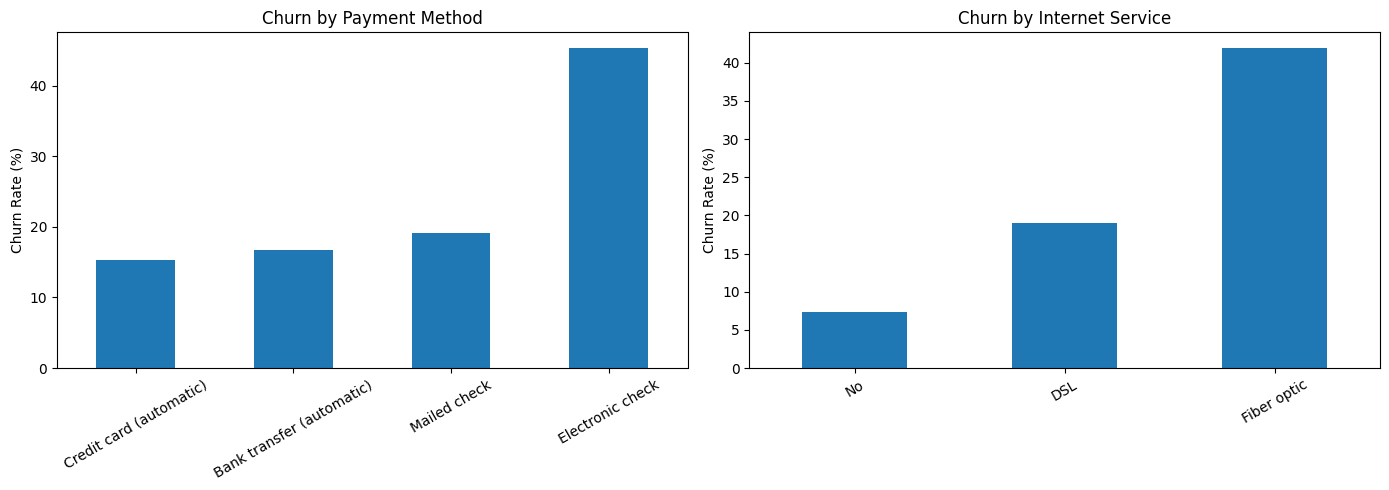

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column, title in [
    (axes[0], "PaymentMethod", "Churn by Payment Method"),
    (axes[1], "InternetService", "Churn by Internet Service")
]:
    rates = (
        pd.crosstab(df_clean[column], df_clean["Churn"], normalize="index")
        * 100
    )

    rates["Yes"].sort_values().plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [35]:
contract_payment = pd.crosstab(
    df_clean["Contract"],
    df_clean["PaymentMethod"],
    normalize="index"
) * 100

display(contract_payment.round(2))

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,15.20,14.01,47.74,23.05
One year,26.54,27.02,23.56,22.88
Two year,33.27,34.28,9.91,22.54


In [46]:
contract_internet = pd.crosstab(
    df_clean["Contract"],
    df_clean["InternetService"],
    normalize="index"
) * 100

display(contract_internet.round(2))

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,31.56,54.92,13.52
One year,38.70,36.59,24.71
Two year,37.05,25.31,37.64


In [37]:
df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr().round(3)

,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


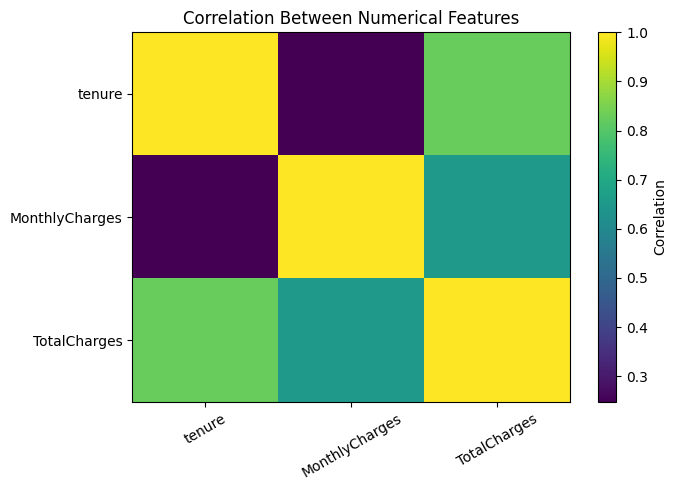

In [44]:
correlation = df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()
#sns.heatmap(correlation, cmap='vlag', annot=True, vmin=-1, vmax=1)

plt.figure(figsize=(7, 5))
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=30)
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [47]:
from sklearn.model_selection import train_test_split

# Target: what we want the model to predict
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Features: information used to predict churn
X = df_clean.drop(columns=["Churn", "customerID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Stayed", 1: "Churned"}))

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
Stayed     5174
Churned    1869
Name: count, dtype: int64


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn rate: 26.54 %
Testing churn rate: 26.54 %


In [49]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nNumber of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [51]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [52]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Complete Logistic Regression pipeline created!")

Complete Logistic Regression pipeline created!


In [53]:
# Train the complete pipeline on training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [54]:
# Predict churn class: 0 = stayed, 1 = churned
y_pred = logistic_model.predict(X_test)

# Predict probability of churn
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 actual outcomes:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(y_prob[:10].round(3).tolist())

Predictions generated successfully!

First 10 actual outcomes:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted outcomes:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]

First 10 churn probabilities:
[0.046, 0.684, 0.059, 0.402, 0.021, 0.603, 0.448, 0.13, 0.003, 0.395]


In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("MODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



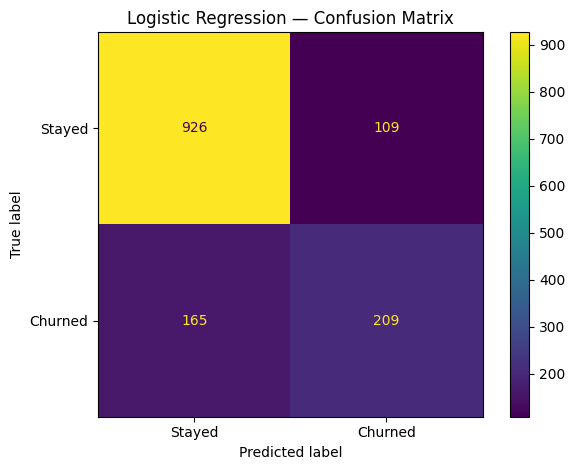

In [56]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    values_format="d"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [57]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

print("Random Forest model pipeline created successfully!")

Random Forest model pipeline created successfully!


In [58]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [59]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully!")

print("\nFirst 10 actual outcomes:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted outcomes:")
print(y_pred_rf[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(y_prob_rf[:10].round(3).tolist())

Random Forest predictions generated successfully!

First 10 actual outcomes:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted outcomes:
[0, 1, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 churn probabilities:
[0.0, 0.705, 0.075, 0.29, 0.005, 0.385, 0.405, 0.115, 0.0, 0.435]


In [60]:
print("RANDOM FOREST MODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

RANDOM FOREST MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.7828
Precision: 0.6189
Recall: 0.4733
F1-score: 0.5364
ROC-AUC: 0.8232

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.82      0.89      0.86      1035
     Churned       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



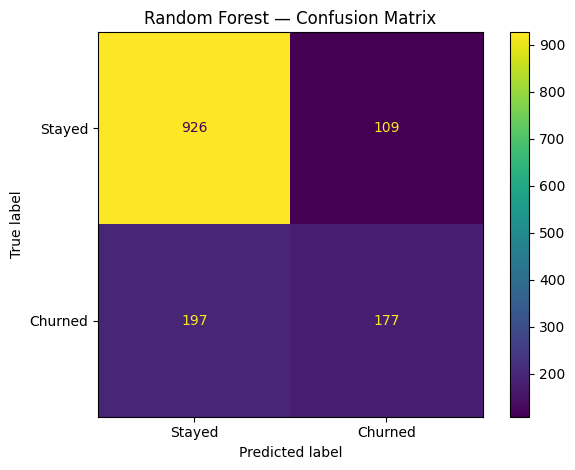

In [61]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Stayed", "Churned"],
    values_format="d"
)

plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

In [62]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_comparison = model_comparison.round(4)
model_comparison

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232


**Understanding Feature Importance**

In [63]:
# Get the trained Logistic Regression classifier
lr_classifier = logistic_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get the learned coefficients
coefficients = lr_classifier.coef_[0]

# Create a DataFrame for interpretation
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df.head(10)

,Feature,Coefficient
0,num__SeniorCitizen,0.053449
1,num__tenure,-1.257539
2,num__MonthlyCharges,-0.591863
3,num__TotalCharges,0.536253
4,cat__gender_Female,-0.168134
5,cat__gender_Male,-0.146421
6,cat__Partner_No,-0.167425
7,cat__Partner_Yes,-0.147130
8,cat__Dependents_No,-0.046067
9,cat__Dependents_Yes,-0.268487


In [64]:
coefficient_df["Abs_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df.sort_values(
    "Abs_Coefficient",
    ascending=False
).head(15)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.257539,1.257539
38,cat__Contract_Two year,-0.776594,0.776594
15,cat__InternetService_DSL,-0.648646,0.648646
16,cat__InternetService_Fiber optic,0.634195,0.634195
2,num__MonthlyCharges,-0.591863,0.591863
36,cat__Contract_Month-to-month,0.582883,0.582883
3,num__TotalCharges,0.536253,0.536253
39,cat__PaperlessBilling_No,-0.343227,0.343227
25,cat__DeviceProtection_No internet service,-0.300104,0.300104
17,cat__InternetService_No,-0.300104,0.300104


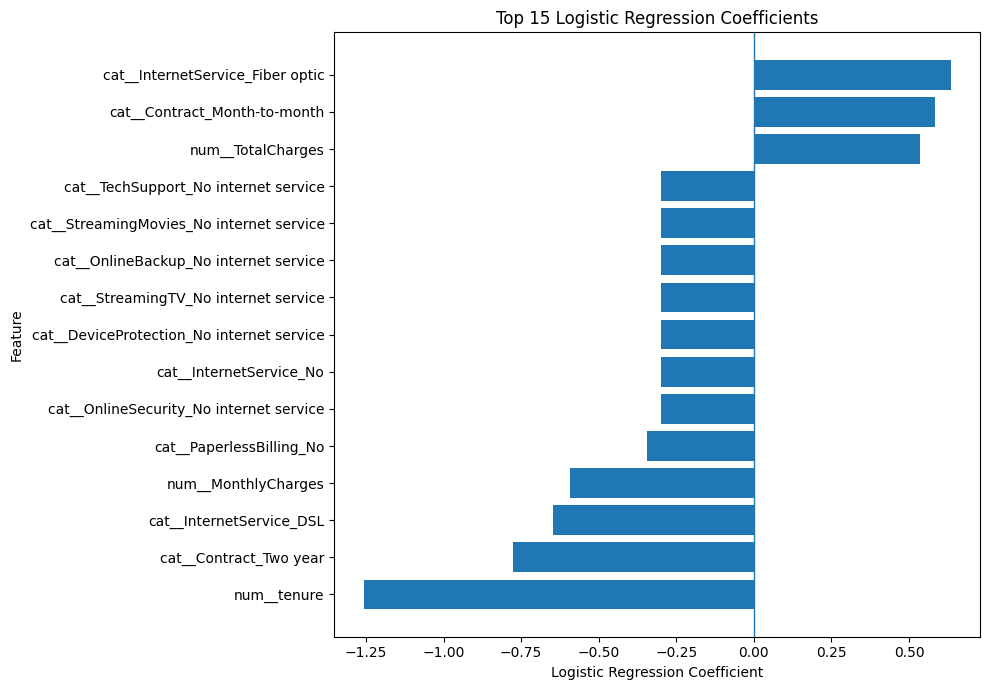

In [65]:
top_features = (
    coefficient_df
    .sort_values("Abs_Coefficient", ascending=False)
    .head(15)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

In [66]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [67]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [68]:
# Transform test data using the fitted preprocessing step
X_test_transformed = logistic_model.named_steps[
    "preprocessor"
].transform(X_test)

# Get the transformed feature names
feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

print("Transformed test data shape:", X_test_transformed.shape)
print("Number of feature names:", len(feature_names))

Transformed test data shape: (1409, 45)
Number of feature names: 45


In [69]:
explainer = shap.LinearExplainer(
    logistic_model.named_steps["classifier"],
    logistic_model.named_steps["preprocessor"].transform(X_train)
)

shap_values = explainer(
    X_test_transformed
)

print("SHAP values calculated successfully!")

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


SHAP values calculated successfully!


**SHAP Explainability**

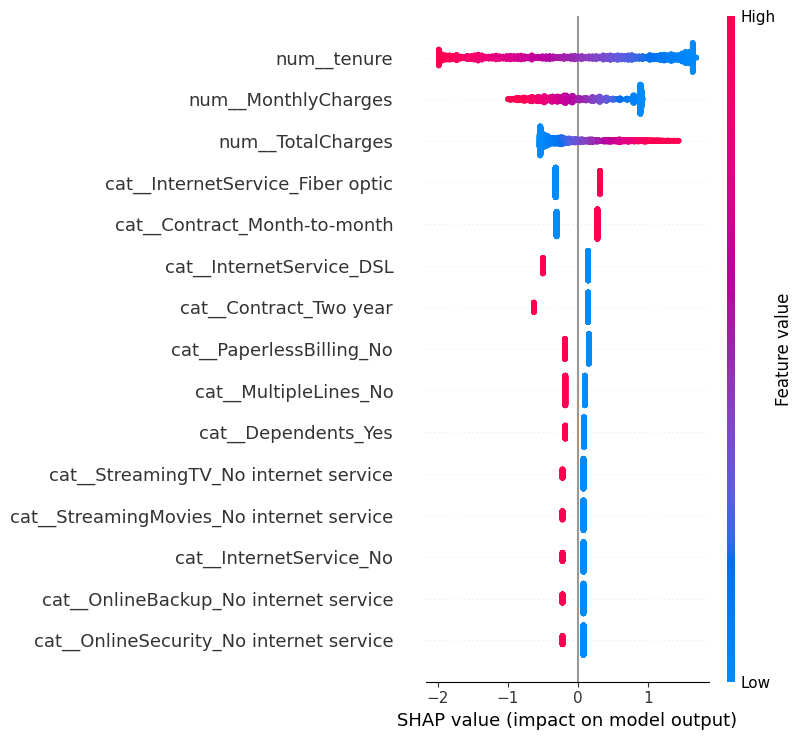

In [70]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=15
)

In [71]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.head(15)

,Feature,Mean_Absolute_SHAP
0,num__tenure,1.124810
1,num__MonthlyCharges,0.506224
2,num__TotalCharges,0.440502
3,cat__InternetService_Fiber optic,0.317098
4,cat__Contract_Month-to-month,0.290308
5,cat__InternetService_DSL,0.269508
6,cat__Contract_Two year,0.262372
7,cat__PaperlessBilling_No,0.168973
8,cat__MultipleLines_No,0.139725
9,cat__Dependents_Yes,0.116524


**Revenue at Risk Analysis**

In [74]:
# Create a copy of the test data for revenue analysis
revenue_analysis = X_test.copy()

# Add actual churn status
revenue_analysis["Actual_Churn"] = y_test

# Add predicted churn status from Logistic Regression
revenue_analysis["Predicted_Churn"] = y_pred

# Add predicted churn probability
revenue_analysis["Churn_Probability"] = y_prob

# Display the first 5 rows
revenue_analysis.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.045920
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.683713
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.058940
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0,0.401835
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.021424


In [75]:
# Select customers predicted to churn
predicted_churners = revenue_analysis[
    revenue_analysis["Predicted_Churn"] == 1
]

# Count customers predicted to churn
customers_at_risk = len(predicted_churners)

# Sum their monthly charges
monthly_revenue_at_risk = predicted_churners["MonthlyCharges"].sum()

print("Customers predicted to churn:", customers_at_risk)
print("Monthly revenue at risk:", round(monthly_revenue_at_risk, 2))


Customers predicted to churn: 318
Monthly revenue at risk: 25211.65


In [77]:
#to verify calculations of revenue risk

print("Number of predicted churners:", len(predicted_churners))

print(
    "Average monthly charge:",
    round(predicted_churners["MonthlyCharges"].mean(), 2)
)

print(
    "Total monthly revenue at risk:",
    round(predicted_churners["MonthlyCharges"].sum(), 2)
)

Number of predicted churners: 318
Average monthly charge: 79.28
Total monthly revenue at risk: 25211.65


In [78]:
# Select customers who actually churned
actual_churners = revenue_analysis[
    revenue_analysis["Actual_Churn"] == 1
]

# Count customers who actually churned
actual_churn_count = len(actual_churners)

# Calculate their total monthly charges
actual_monthly_revenue = actual_churners["MonthlyCharges"].sum()

print("Customers who actually churned:", actual_churn_count)
print(
    "Monthly charges associated with actual churn:",
    round(actual_monthly_revenue, 2)
)


Customers who actually churned: 374
Monthly charges associated with actual churn: 27214.9


In [79]:
print("Revenue comparison on the test dataset")
print("----------------------------------------")
print(
    "Predicted churn revenue:",
    round(predicted_churners["MonthlyCharges"].sum(), 2)
)
print(
    "Actual churn revenue:",
    round(actual_churners["MonthlyCharges"].sum(), 2)
)
print(
    "Customers predicted to churn:",
    len(predicted_churners)
)
print(
    "Customers who actually churned:",
    len(actual_churners)
)


Revenue comparison on the test dataset
----------------------------------------
Predicted churn revenue: 25211.65
Actual churn revenue: 27214.9
Customers predicted to churn: 318
Customers who actually churned: 374


In [80]:
# Customers who actually churned AND were predicted to churn
correctly_predicted_churners = revenue_analysis[
    (revenue_analysis["Actual_Churn"] == 1) &
    (revenue_analysis["Predicted_Churn"] == 1)
]

# Count correctly identified churners
correct_churn_count = len(correctly_predicted_churners)

# Sum their monthly charges
correct_churn_revenue = (
    correctly_predicted_churners["MonthlyCharges"].sum()
)

print("Correctly identified churners:", correct_churn_count)
print(
    "Monthly charges of correctly identified churners:",
    round(correct_churn_revenue, 2)
)


Correctly identified churners: 209
Monthly charges of correctly identified churners: 16436.3


In [81]:
# Create a Power BI dataset from the test customers
powerbi_data = revenue_analysis.copy()

# Add a readable actual churn label
powerbi_data["Actual_Churn_Label"] = (
    powerbi_data["Actual_Churn"].map({0: "No", 1: "Yes"})
)

# Add a readable prediction label
powerbi_data["Predicted_Churn_Label"] = (
    powerbi_data["Predicted_Churn"].map({0: "No", 1: "Yes"})
)

# Add monthly charges for customers predicted to churn
powerbi_data["Revenue_At_Risk"] = (
    powerbi_data["MonthlyCharges"] *
    powerbi_data["Predicted_Churn"]
)

# Add monthly charges for customers who actually churned
powerbi_data["Actual_Churn_Revenue"] = (
    powerbi_data["MonthlyCharges"] *
    powerbi_data["Actual_Churn"]
)

# Display the prepared dataset
powerbi_data.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Actual_Churn_Label,Predicted_Churn_Label,Revenue_At_Risk,Actual_Churn_Revenue
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Credit card (automatic),114.05,8468.20,0,0,0.045920,No,No,0.00,0.0
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Credit card (automatic),100.15,908.55,0,1,0.683713,No,Yes,100.15,0.0
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),78.35,3211.20,0,0,0.058940,No,No,0.00,0.0
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Electronic check,78.20,1468.75,0,0,0.401835,No,No,0.00,0.0
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),82.65,5919.35,0,0,0.021424,No,No,0.00,0.0


In [82]:
# Define your project's processed data folder
output_folder = Path(
    r"C:\Users\SHIVANI SAPKAL\Desktop\Data Science mini\Customer Churn Analysis and Prediction\data\processed"
)

# Create the folder if it does not already exist
output_folder.mkdir(parents=True, exist_ok=True)

# Define the output file path
output_file = output_folder / "customer_churn_powerbi.csv"

# Save the dataset
powerbi_data.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File location:", output_file)
print("Dataset shape:", powerbi_data.shape)


Dataset saved successfully!
File location: C:\Users\SHIVANI SAPKAL\Desktop\Data Science mini\Customer Churn Analysis and Prediction\data\processed\customer_churn_powerbi.csv
Dataset shape: (1409, 26)


In [83]:
# Read the saved CSV back into pandas
powerbi_check = pd.read_csv(output_file)

print("Saved file rows and columns:", powerbi_check.shape)
print("\nColumn names:")
print(powerbi_check.columns.tolist())

print("\nMissing values:")
print(powerbi_check.isnull().sum().sum())


Saved file rows and columns: (1409, 26)

Column names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Actual_Churn', 'Predicted_Churn', 'Churn_Probability', 'Actual_Churn_Label', 'Predicted_Churn_Label', 'Revenue_At_Risk', 'Actual_Churn_Revenue']

Missing values:
0


In [84]:
# Use all cleaned customer records as the base
powerbi_all = df_clean.copy()

# Predict churn for all customers using the trained Logistic Regression model
powerbi_all["Predicted_Churn"] = logistic_model.predict(X)

# Calculate each customer's predicted churn probability
powerbi_all["Churn_Probability"] = logistic_model.predict_proba(X)[:, 1]

# Add readable churn labels
powerbi_all["Actual_Churn_Label"] = powerbi_all["Churn"]

powerbi_all["Predicted_Churn_Label"] = (
    powerbi_all["Predicted_Churn"].map({0: "No", 1: "Yes"})
)

# Estimate monthly charges associated with predicted churners
powerbi_all["Revenue_At_Risk"] = (
    powerbi_all["MonthlyCharges"] * powerbi_all["Predicted_Churn"]
)

# Display the result
print("Rows:", powerbi_all.shape[0])
print("Columns:", powerbi_all.shape[1])
powerbi_all.head()


Rows: 7043
Columns: 26


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Predicted_Churn,Churn_Probability,Actual_Churn_Label,Predicted_Churn_Label,Revenue_At_Risk
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Yes,Electronic check,29.85,29.85,No,1,0.613717,No,Yes,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,Mailed check,56.95,1889.50,No,0,0.044497,No,No,0.00
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Yes,Mailed check,53.85,108.15,Yes,0,0.299185,Yes,No,0.00
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,Bank transfer (automatic),42.30,1840.75,No,0,0.028452,No,No,0.00
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Yes,Electronic check,70.70,151.65,Yes,1,0.691580,Yes,Yes,70.70


In [85]:
# Save the full customer dataset for Power BI
full_output_file = output_folder / "customer_churn_powerbi_all.csv"

powerbi_all.to_csv(full_output_file, index=False)

print("Full dataset saved successfully!")
print("File location:", full_output_file)
print("Dataset shape:", powerbi_all.shape)


Full dataset saved successfully!
File location: C:\Users\SHIVANI SAPKAL\Desktop\Data Science mini\Customer Churn Analysis and Prediction\data\processed\customer_churn_powerbi_all.csv
Dataset shape: (7043, 26)
